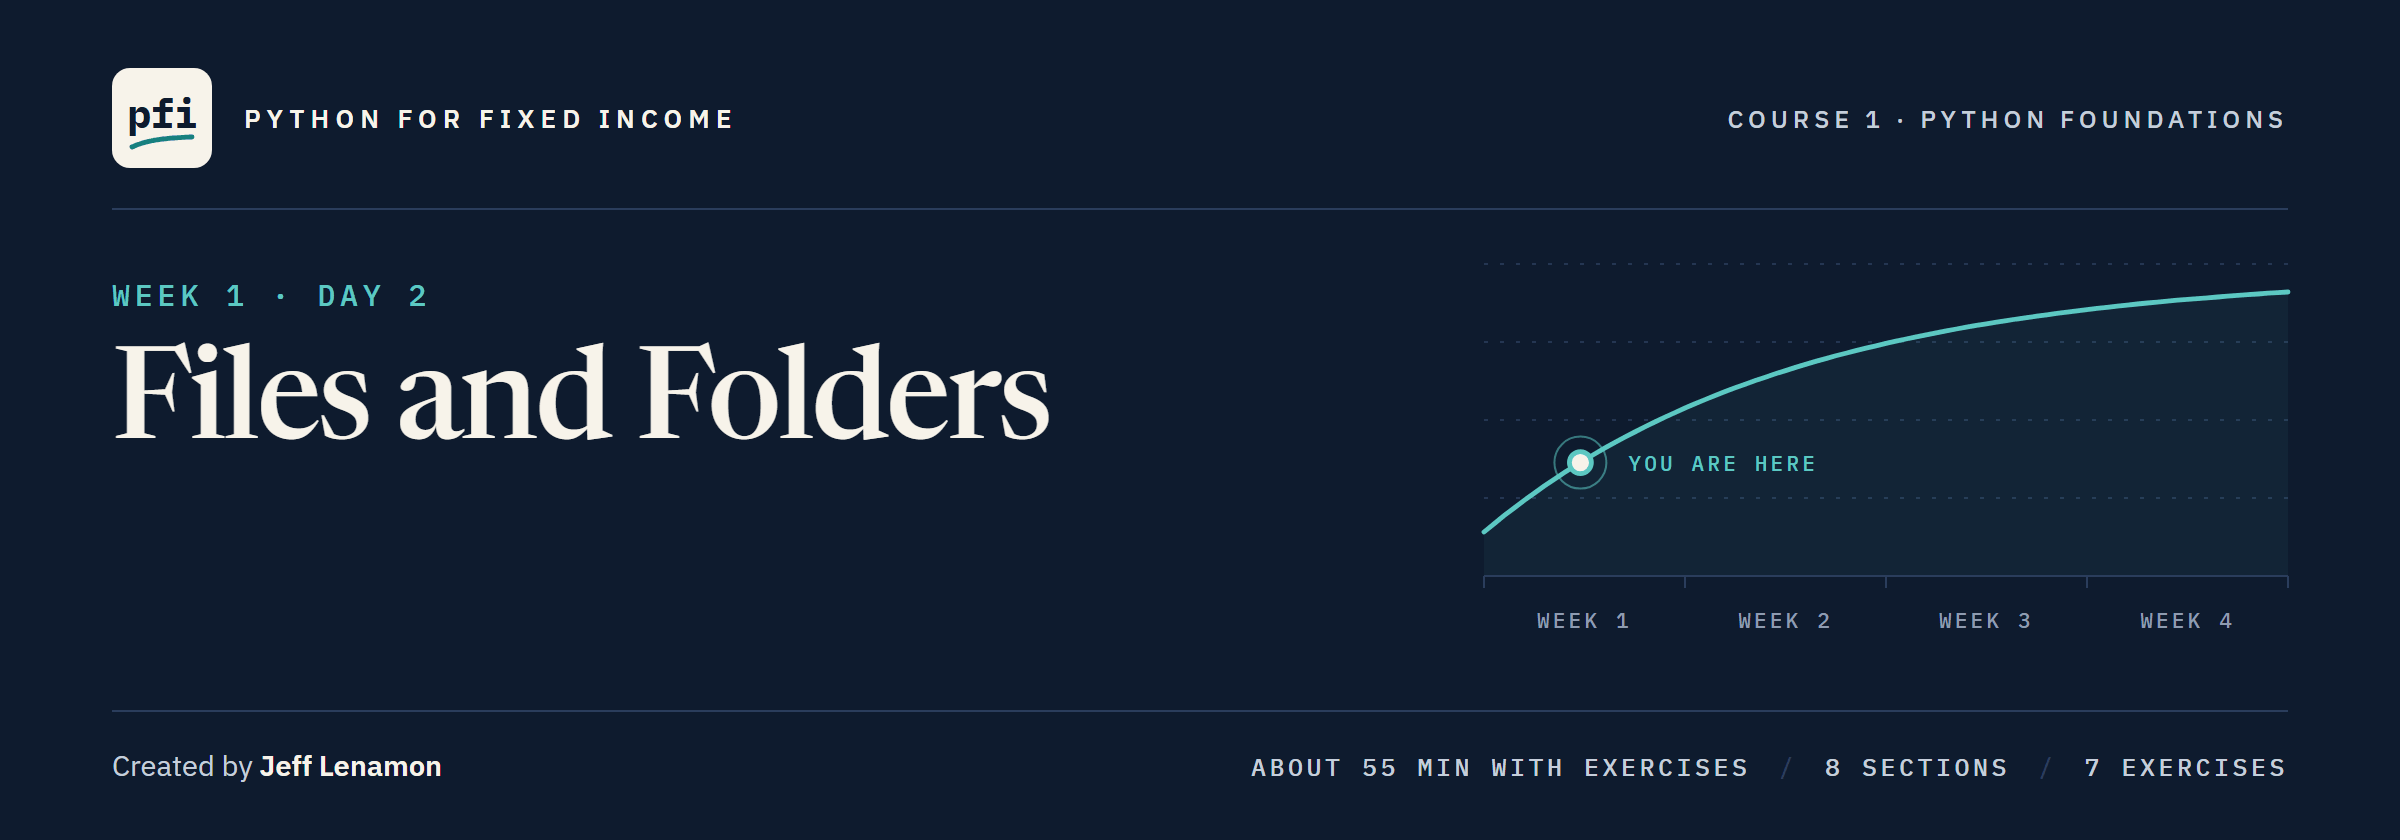

# Files and Folders

Week 1, Day 2. Using Python to find, create, and organize the files a bond desk works with.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day2/02_files_and_folders.ipynb)

## The Desk Lead's Fourth Note

Part 2's note is answered, and a fourth one is waiting:

> The book lives only while your notebook runs: restart it and the four bonds are gone. Give it a folder of its own, write it to a file there, and show me it reads back to 3,000,000 face and 2,958,750 dollars of cost.

### The Book in One Cell

**A new notebook starts empty: run the next cell to store Part 1's four lists again.**

In [1]:
# Part 1's lists, one per column, the bonds in the same order
ticker_list = ['QVNE', 'DNMR', 'PLWK', 'HLVF']
coupon_list = [5.25, 6.125, 4.75, 7.5]
price_list = [98.5, 103.25, 95.0, 101.0]
face_list = [1500000, 500000, 750000, 250000]
print(f'The desk holds {len(ticker_list)} bonds and {sum(face_list):,} face')

The desk holds 4 bonds and 3,000,000 face


## Your Route Through Day 2

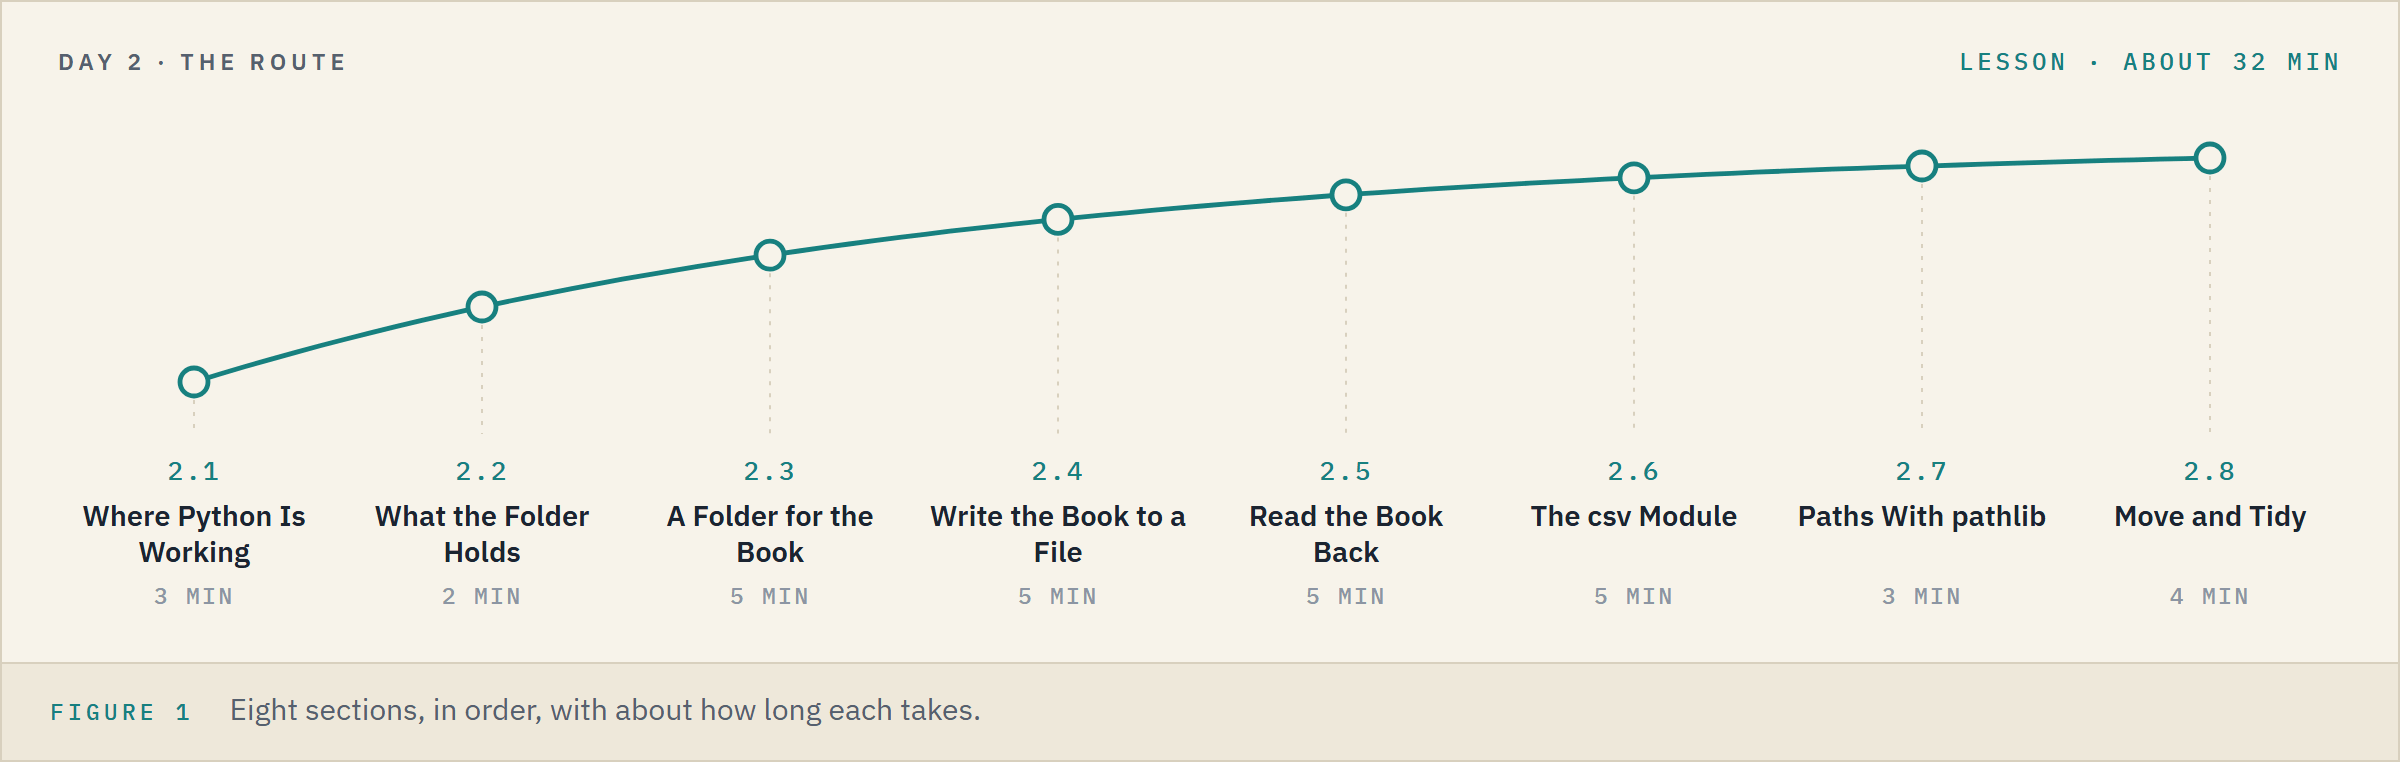

**Time.** About 32 minutes for the lesson, then about 21 for the seven exercises.

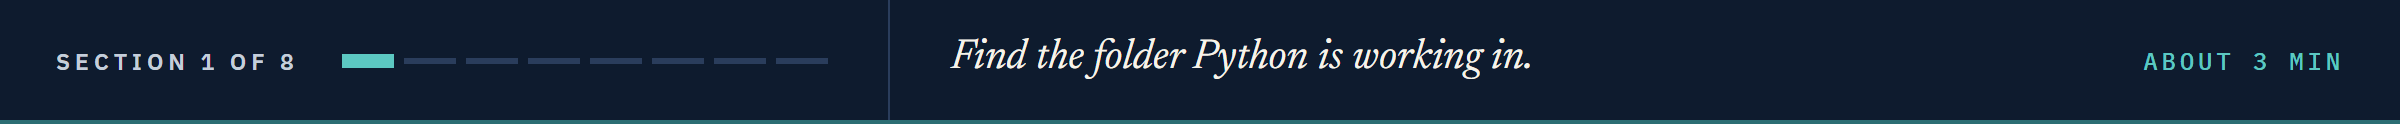

## 2.1 Where Python Is Working

### Which System, Which Folder

`os` is a **module**: a library that comes with Python, like Day 0's `statistics`.
It talks to the **operating system** (Windows, macOS, Linux), which keeps the files and folders.

Q. Which operating system is this notebook running on?

Python reads and writes files from one folder at a time: the **working directory** (**directory** is another word for folder).
A file name with no folder in front is looked for there.

Q. Which folder is Python working in right now?

Q. What is the name of just the last folder?

In [2]:
# load the os module
import os
# os.name holds a short code for the operating system
print(os.name)

nt


In [3]:
# getcwd stands for 'get current working directory'
print(os.getcwd())

In [4]:
# basename keeps only the last part of a path
print(os.path.basename(os.getcwd()))

day2


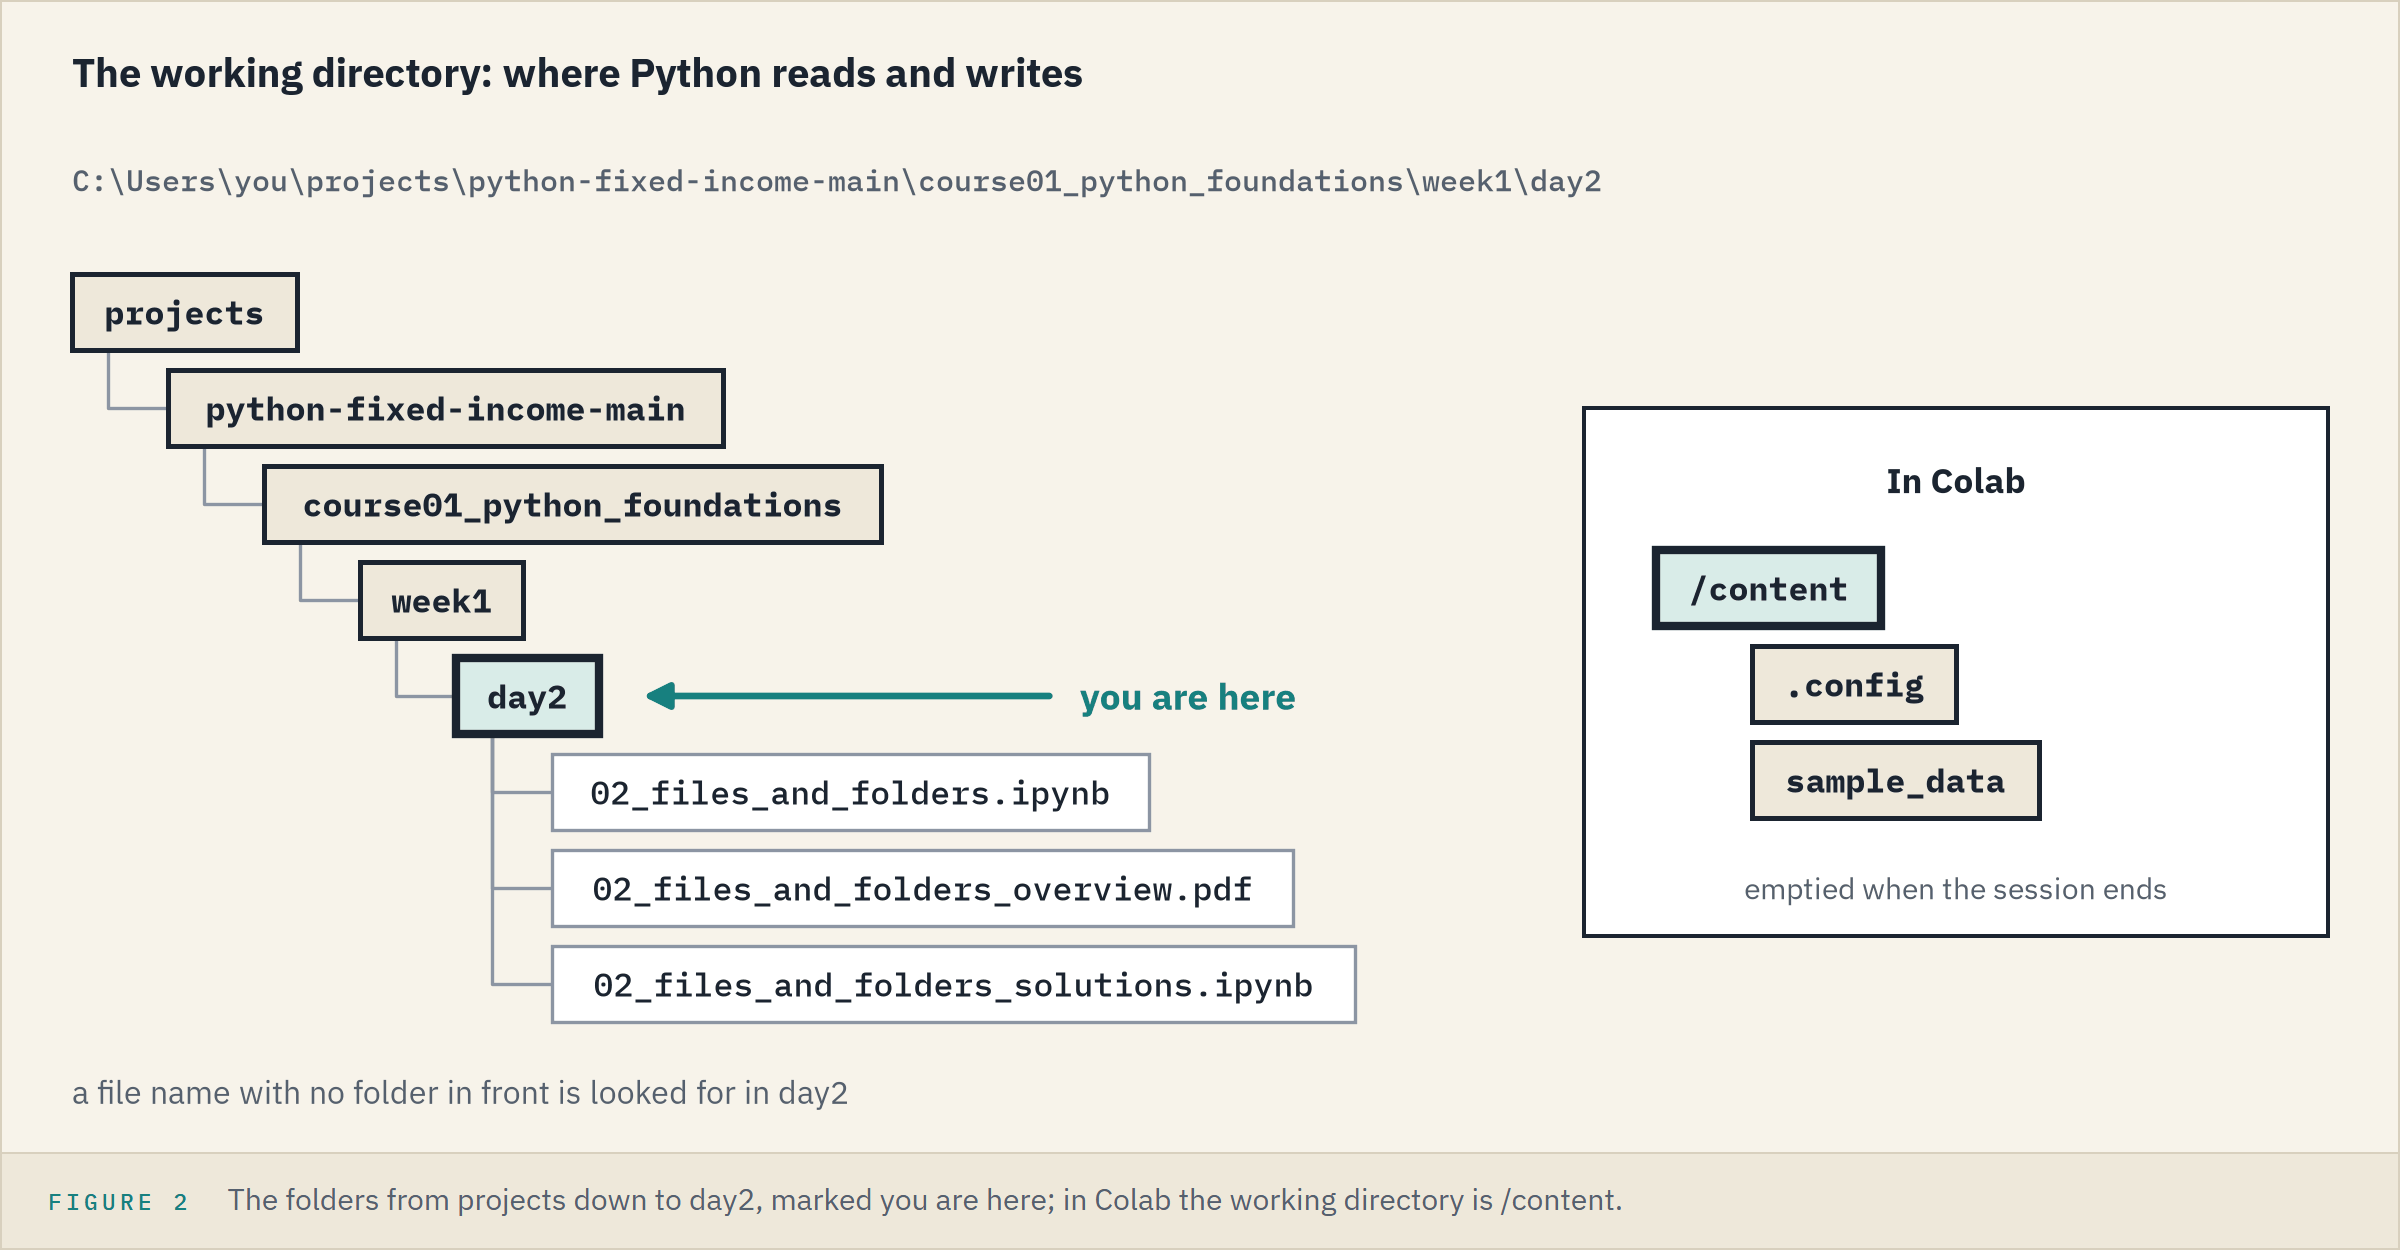

`nt` means Windows; `posix` means macOS or Linux, Google Colab included.
`getcwd()` prints a **path**: every folder from the top of the drive down to this one.
Yours differs from anyone else's, so no output is saved here.
On your own machine VS Code starts Python in the notebook's own folder, `day2`.
In Colab it is `/content`, a temporary folder emptied when the session ends, so `basename()` prints `content`.

**Excel side by side.** In desktop Excel, `=CELL("filename",A1)` shows a saved workbook's full path, file and sheet name at the end.

**Now look inside it.**

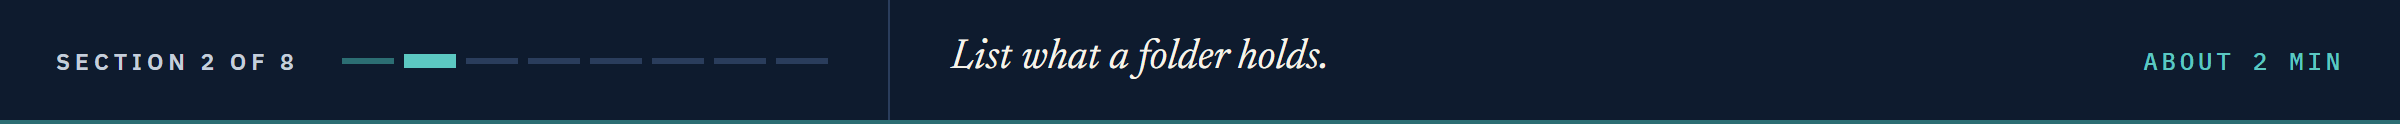

## 2.2 What the Folder Holds

### List the Folder, Walk the Names

Q. What is in the working directory, and how many items?

Q. Print each name on its own line, then keep only the notebooks.

In [5]:
# '.' means the working directory; listdir() lists what is in it
names = os.listdir('.')
print(names)
# len() counts the items, as in Part 1
print(len(names))

['02_files_and_folders.ipynb', '02_files_and_folders_overview.pdf', '02_files_and_folders_solutions.ipynb']
3


In [6]:
# a for loop over the list, as in Part 2
for name in names:
    print(name)
# endswith() checks how a string ends: notebook files end in .ipynb
notebooks = [name for name in names if name.endswith('.ipynb')]
print(notebooks)

02_files_and_folders.ipynb
02_files_and_folders_overview.pdf
02_files_and_folders_solutions.ipynb
['02_files_and_folders.ipynb', '02_files_and_folders_solutions.ipynb']


`listdir()` returns a **list** of names, in no set order: here the notebook, its solutions, and its overview PDF.
Yours may hold more; Colab shows `.config` and `sample_data`.
The filter dropped the PDF (in Colab, an empty list).

**The book needs a folder of its own in here.**

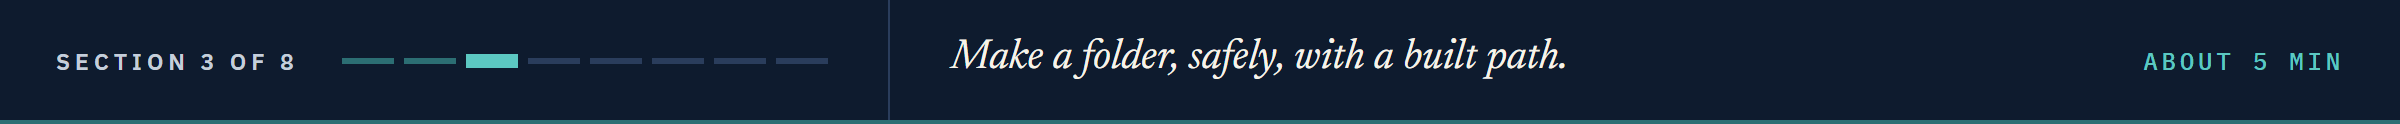

## 2.3 A Folder for the Book

### Start Clean, Then Make the Folder

This notebook makes folders as it goes; the first cell below clears any left by an earlier run, so Run All works every time.
`shutil.rmtree()` deletes a folder and everything in it at once, with no recycle bin and no question: point it only at a folder your own code made.

Q. Clear anything an earlier run left.

Q. Create a folder named 'desk_holdings', then check that it is there.

In [7]:
# shutil also comes with Python; rmtree() removes a folder and everything in it
import shutil
# ignore_errors=True: do nothing if the folder is not there
shutil.rmtree('desk_holdings', ignore_errors=True)

In [8]:
# mkdir stands for 'make directory'
os.mkdir('desk_holdings')
# exists() is True if the folder or file is there
print(os.path.exists('desk_holdings'))

True


`mkdir()` printed nothing: many commands that change something work quietly, so `exists()` checks.

**Run it twice and Python objects.**

### The Same Folder Twice

Q. What happens if we create the same folder again?

Q. Create the folder only if it is not there yet.

In [9]:
# the folder is already there: this cell is meant to fail
os.mkdir('desk_holdings')

FileExistsError: [WinError 183] Cannot create a file when that file already exists: 'desk_holdings'

In [10]:
# not flips True and False: if the folder does not exist, make it
if not os.path.exists('desk_holdings'):
    os.mkdir('desk_holdings')
    print('Folder created')
else:
    print('Folder already exists')

Folder already exists


A `FileExistsError`: Python refuses and touches nothing inside.
Colab words the message differently; the error name is the same.
Checking first makes the cell safe to rerun.

**The desk files one folder per day, and a folder inside a folder needs a path.**

### Build a Path, Then Type One by Hand

Q. Build the path to a folder named '2026-10-02' inside 'desk_holdings', then create it.

Q. Print a path to a folder named 'new', typed by hand.

In [11]:
# join() glues the parts together with the right separator
day_folder = os.path.join('desk_holdings', '2026-10-02')
print(day_folder)
os.mkdir(day_folder)
print(os.listdir('desk_holdings'))

desk_holdings\2026-10-02
['2026-10-02']


In [12]:
# a path to a folder named new, typed by hand
print('desk_holdings\new')

desk_holdings
ew


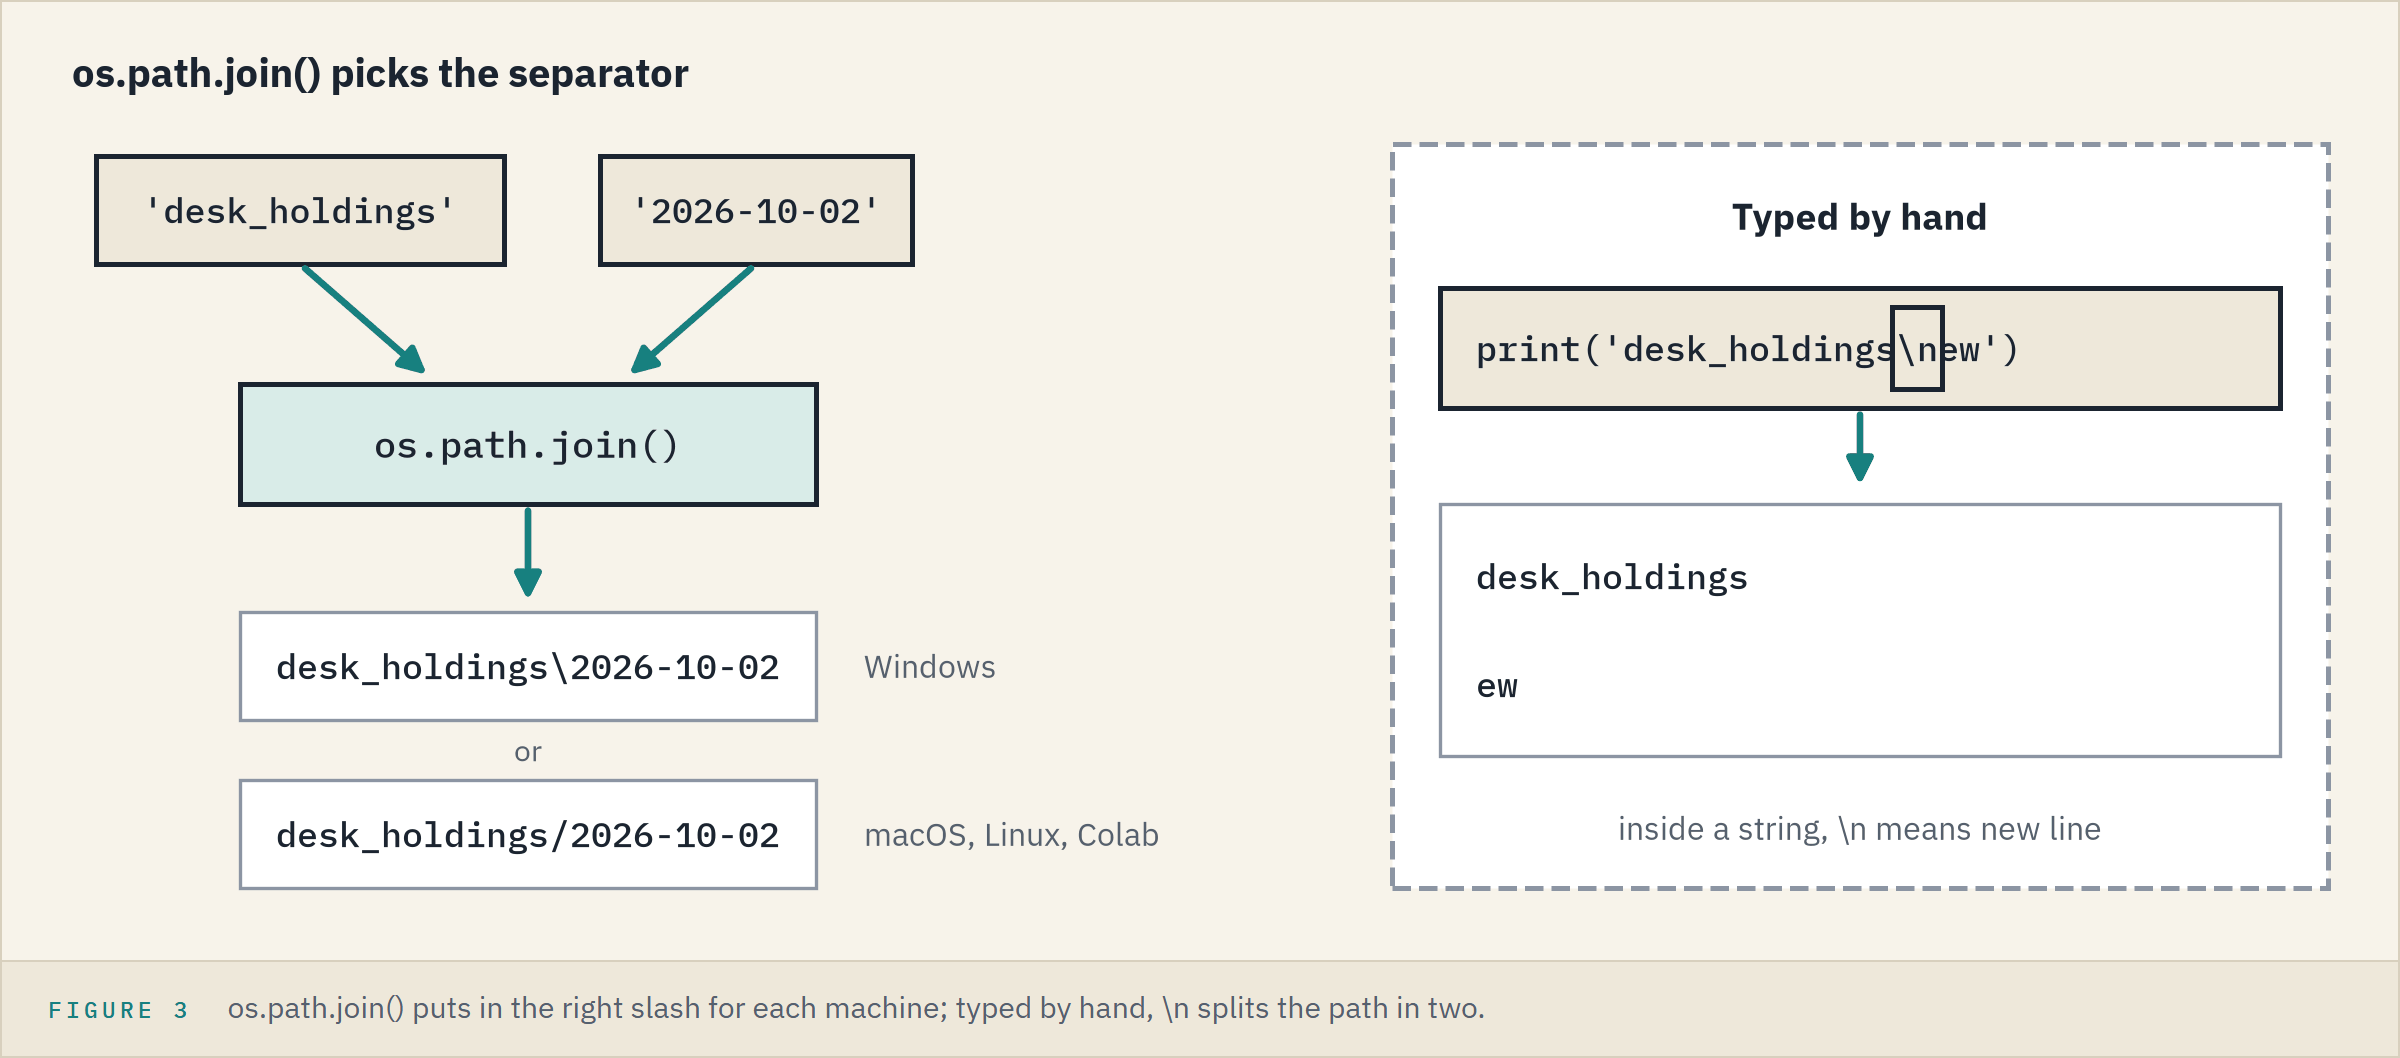

`os.path.join()` picks the machine's separator: a backslash on Windows, a forward slash on macOS, Linux, and Colab.
The same code runs everywhere.
The hand-typed path broke in two: inside a string, `\n` means new line.
Hand-typed Windows paths are a classic bug; `os.path.join()` never has it.
A forward slash works on Windows too, so `'desk_holdings/new'` is safe.

**The folder is ready. Now the file.**

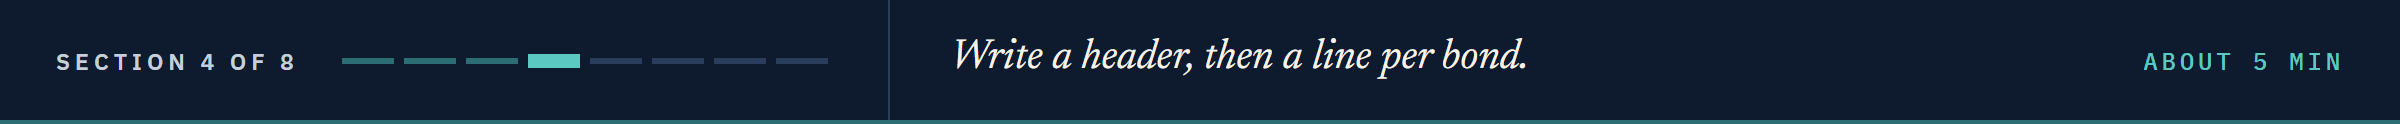

## 2.4 Write the Book to a File

### Open, Write, Close

The book goes into a **CSV** file: plain text, one bond a line, commas between the values.

Q. Build the path to 'holdings.csv' in the dated folder, and write the header line.

In [13]:
file_path = os.path.join(day_folder, 'holdings.csv')
print(file_path)
# open the file for writing: 'w' stands for write
file = open(file_path, 'w', encoding='utf-8')
# write() adds the text exactly as given; \n ends the line
file.write('Ticker,Coupon,Price,Face\n')
# close() finishes the file, so every line is saved
file.close()

desk_holdings\2026-10-02\holdings.csv


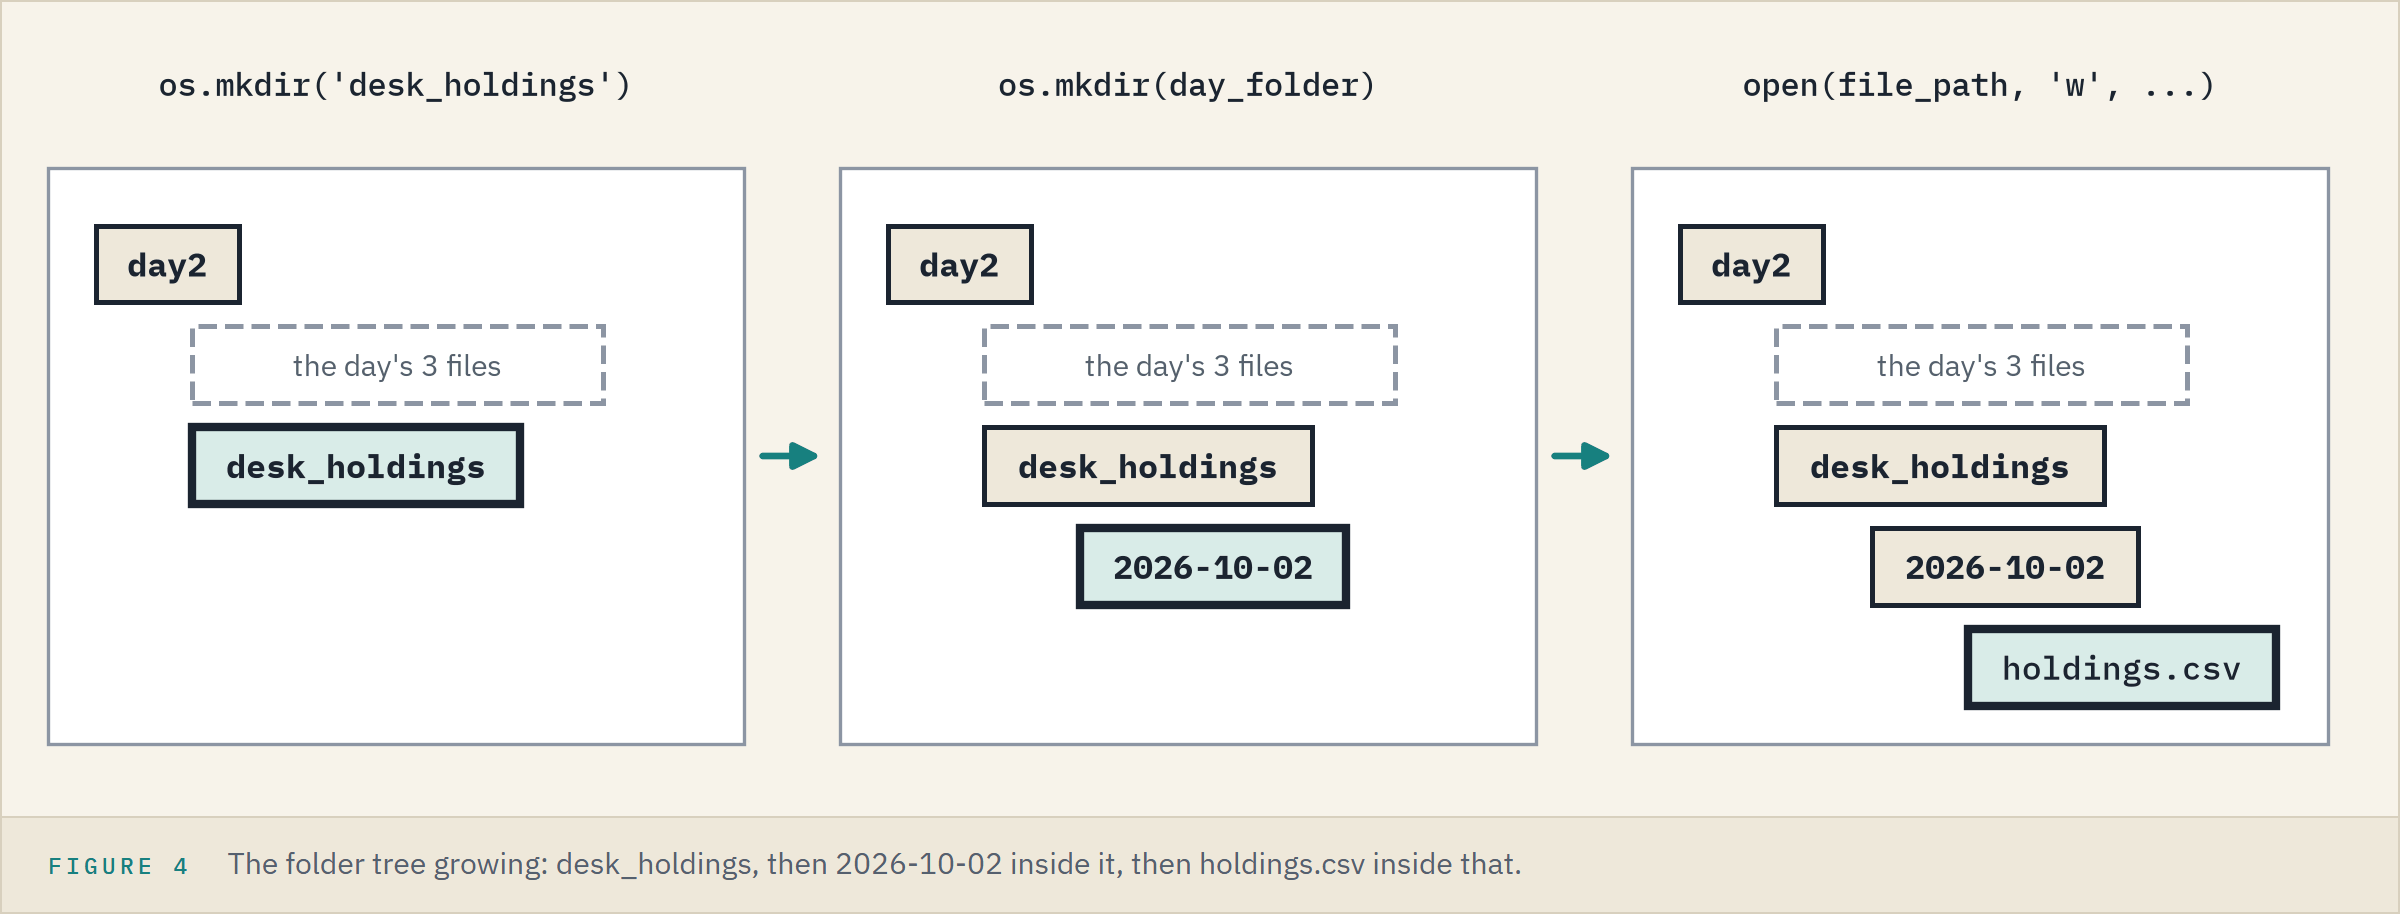

`'w'` creates the file, or wipes it if it is there.
Always give `encoding='utf-8'`: without it Windows uses an older default, and an accented letter or a currency sign can come back wrong on another machine.

**Four bonds by hand is Part 2's problem again: a loop writes them.**

### Let a Loop Write the Bonds

`with` opens a file and closes it by itself when its indented block ends, even if an error stops the block partway.
`'a'` stands for **append**: add to the end and keep what is there.

Q. Append the four bonds with a loop, one line each.

In [14]:
# with open(...) as file: the name file holds the open file until the block ends
with open(file_path, 'a', encoding='utf-8') as file:
    # zip() lines the lists up, as in Part 2: four lists, so four names
    for ticker, coupon, price, face in zip(ticker_list, coupon_list, price_list, face_list):
        file.write(f'{ticker},{coupon},{price},{face}\n')

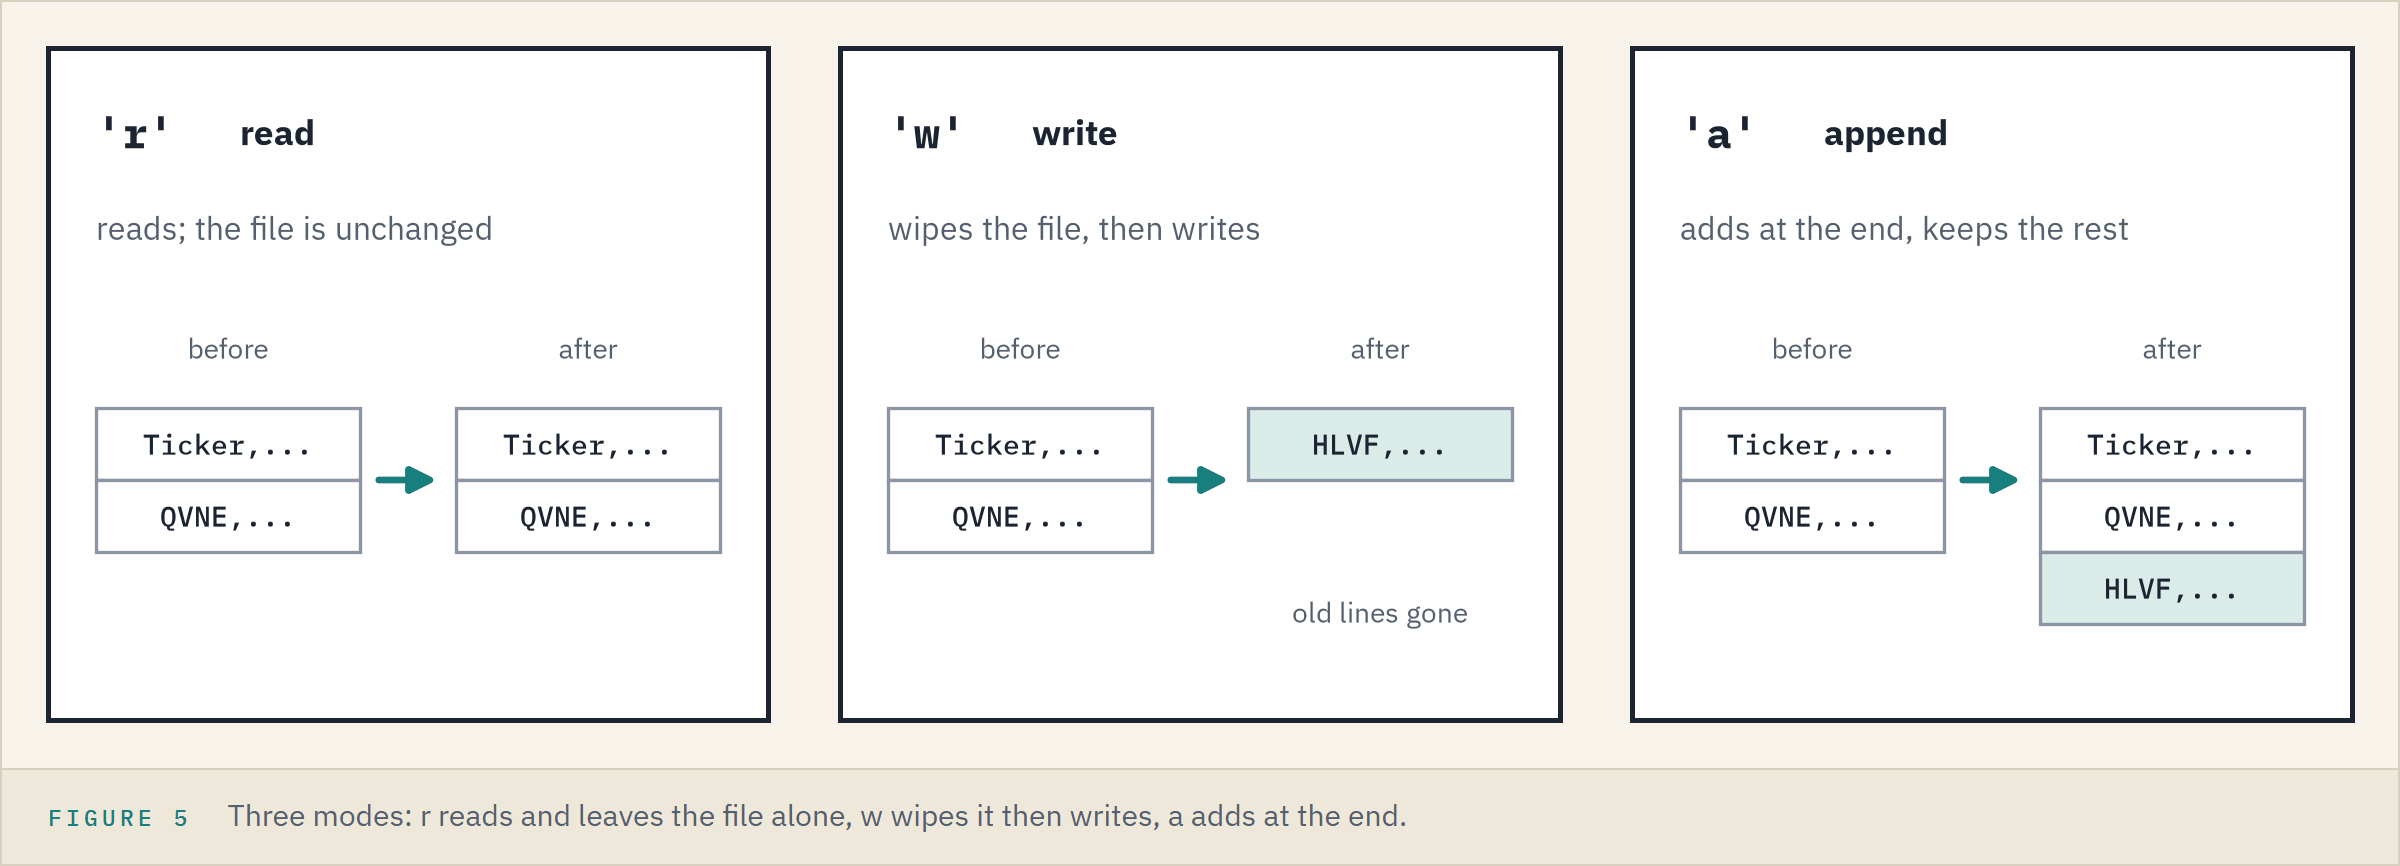

Four bonds from one loop: Part 2's promise kept.
Run that cell twice and the bonds go in twice, since `'a'` always adds; to start over, run the header cell above again.

**Did the loop write what you think? Read the file.**

### Read It Back

Q. Read the whole file back.

In [15]:
# 'r' stands for read; read() returns the whole file as one string
with open(file_path, 'r', encoding='utf-8') as file:
    print(file.read())

Ticker,Coupon,Price,Face
QVNE,5.25,98.5,1500000
DNMR,6.125,103.25,500000
PLWK,4.75,95.0,750000
HLVF,7.5,101.0,250000



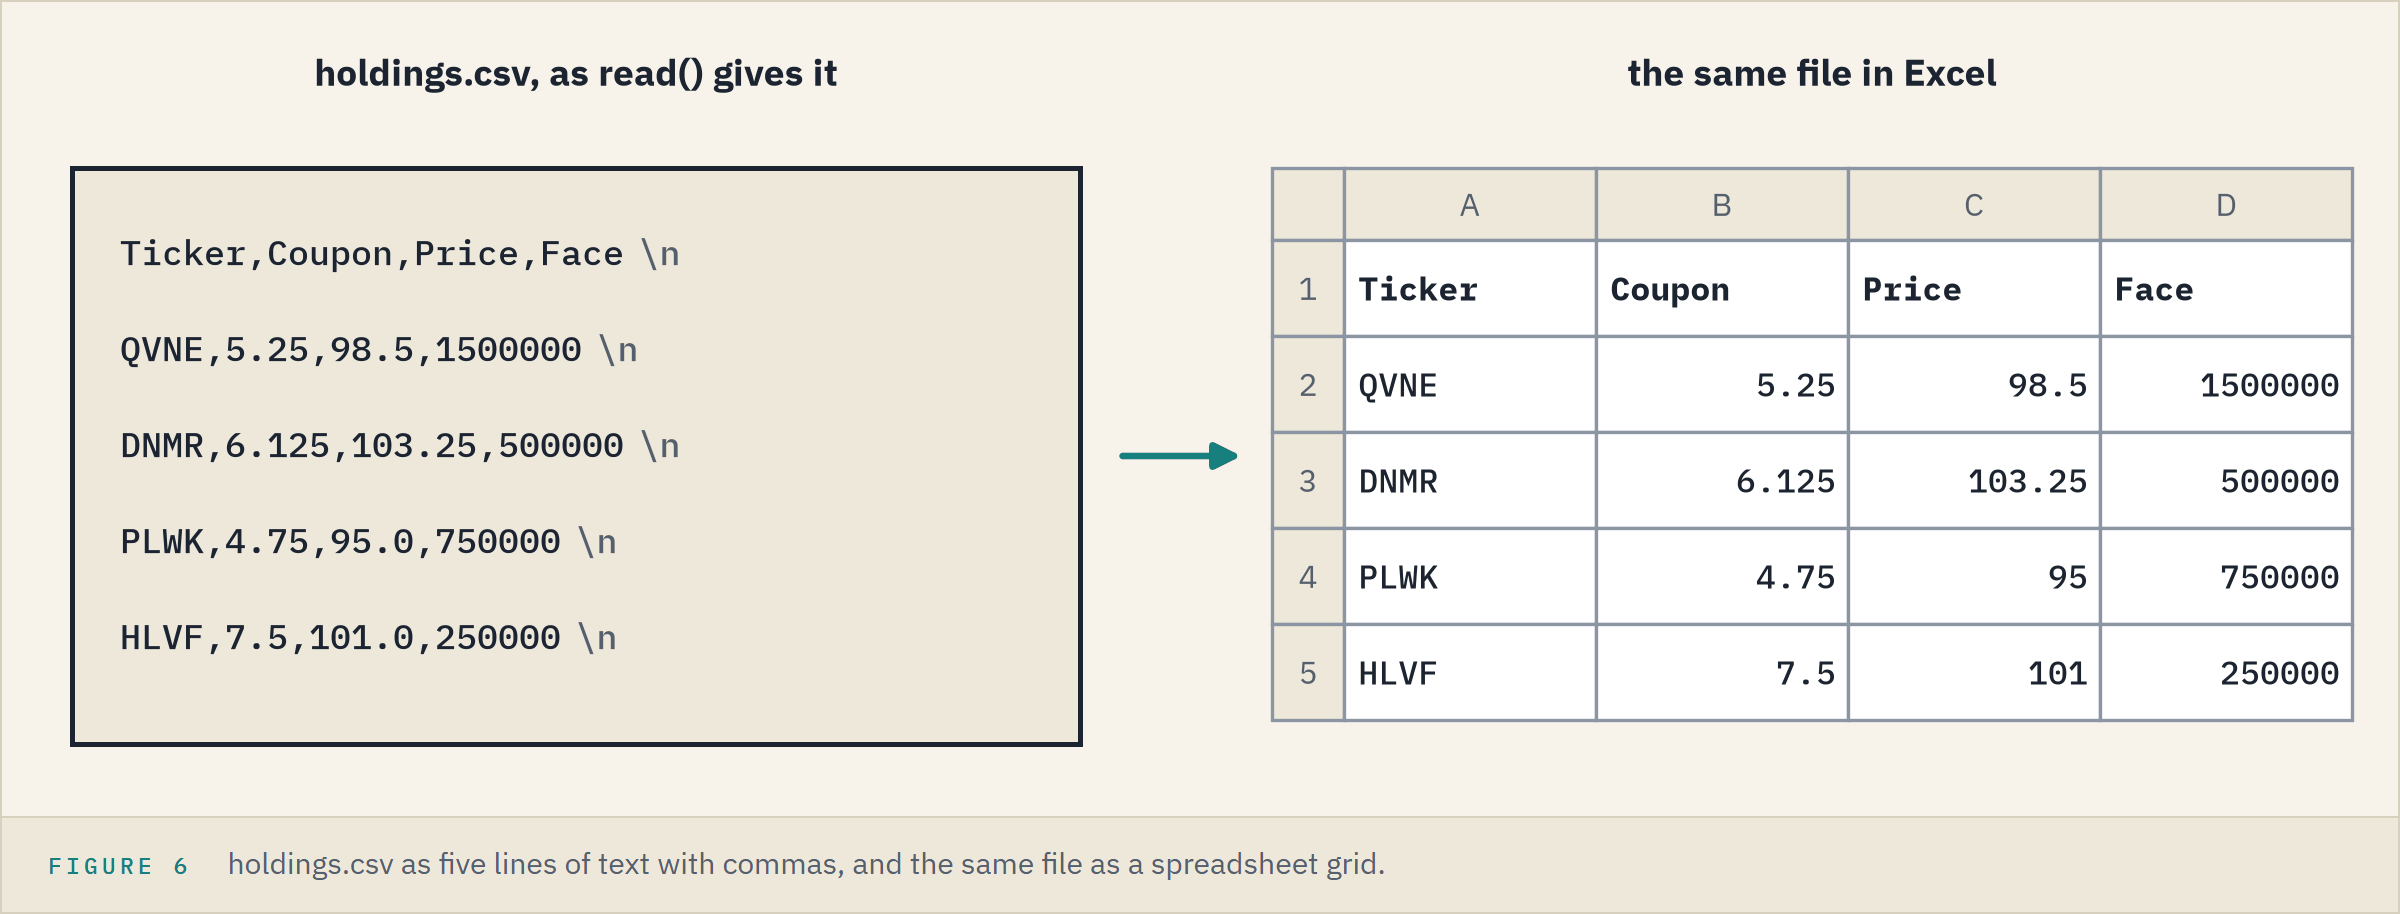

**Excel side by side.** Double-click `holdings.csv` and Excel shows five rows and four columns, splitting each line at the commas.
That holds where Windows' list separator is a comma (US and UK settings); where it is a semicolon, each line lands in one column.

**The book is on disk. Read it back, starting with the classic mistake.**

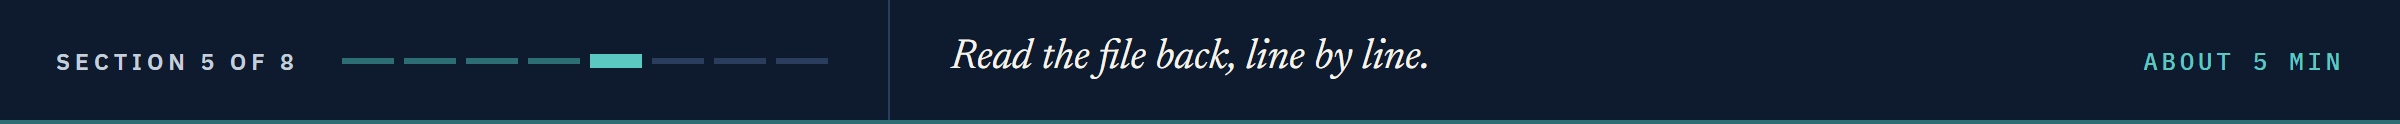

## 2.5 Read the Book Back

### A Wrong Name

Q. Open 'holding.csv', one letter short.

Q. Is a path a file or a folder?

In [16]:
# a typo in the name: this cell is meant to fail
file = open(os.path.join(day_folder, 'holding.csv'), 'r', encoding='utf-8')

FileNotFoundError: [Errno 2] No such file or directory: 'desk_holdings\\2026-10-02\\holding.csv'

In [17]:
# isfile() is True for a file, isdir() for a folder
print(os.path.isfile(file_path))
print(os.path.isdir(file_path))
print(os.path.isdir(day_folder))

True
False
True


A `FileNotFoundError`: the last line gives the path Python looked for, each backslash shown twice inside the quotes.
Check the spelling, then the folder with `os.listdir()`; nothing was damaged.
`isfile()` and `isdir()` tell a file from a folder.

**With the right name, take the file a line at a time.**

### One Line at a Time, Then Split It

Q. How many lines does the file have?

Q. Print each bond's ticker and face.

In [18]:
# readlines() returns a list with one string per line
with open(file_path, 'r', encoding='utf-8') as file:
    lines = file.readlines()
print(len(lines))
print(lines)

5
['Ticker,Coupon,Price,Face\n', 'QVNE,5.25,98.5,1500000\n', 'DNMR,6.125,103.25,500000\n', 'PLWK,4.75,95.0,750000\n', 'HLVF,7.5,101.0,250000\n']


In [19]:
# lines[1:] skips the header, the first item
for line in lines[1:]:
    # strip() drops the \n, and split(',') cuts at each comma
    values = line.strip().split(',')
    print(f'{values[0]} holds {values[3]} face')

QVNE holds 1500000 face
DNMR holds 500000 face
PLWK holds 750000 face
HLVF holds 250000 face


Five lines: a header and four bonds, each still ending in `\n`.
`split(',')` gives a list, the ticker at index 0 and the face at index 3: safe only while no value holds a comma.

**Excel side by side.** `split(',')` is **Text to Columns** on Excel's Data tab, with the comma as the delimiter.

**Now add the face up.**

### Total the Face, Then Forget to Convert

Q. What is the total face in the file?

Q. Run the same total without `int()`.

In [20]:
# add up the face: text from a file is a string, so int() makes it a number first
total_face = 0
for line in lines[1:]:
    values = line.strip().split(',')
    total_face += int(values[3])
print(f'The total face held is {total_face:,}')

The total face held is 3,000,000


In [21]:
# no int(): this cell is meant to fail
total_face = 0
for line in lines[1:]:
    values = line.strip().split(',')
    total_face += values[3]

TypeError: unsupported operand type(s) for +=: 'int' and 'str'

3,000,000, as in the book cell.

One line, step by step, as in Part 1:

<table align="left">
<tr><th align="left">Step</th><th align="left">Gives</th></tr>
<tr><td align="left"><code>line</code></td><td align="left"><code>'QVNE,5.25,98.5,1500000\n'</code>, one string</td></tr>
<tr><td align="left"><code>line.strip()</code></td><td align="left"><code>'QVNE,5.25,98.5,1500000'</code>, the <code>\n</code> gone</td></tr>
<tr><td align="left"><code>.split(',')</code></td><td align="left"><code>['QVNE', '5.25', '98.5', '1500000']</code>, four strings</td></tr>
<tr><td align="left"><code>values[3]</code></td><td align="left"><code>'1500000'</code>, still text: the <code>TypeError</code></td></tr>
<tr><td align="left"><code>int(values[3])</code></td><td align="left"><code>1500000</code>, a number to add</td></tr>
</table>
<br clear="left">

A `TypeError`: Python will not add the text '1500000' to the number 0.

**Splitting at commas has one quiet weakness.**

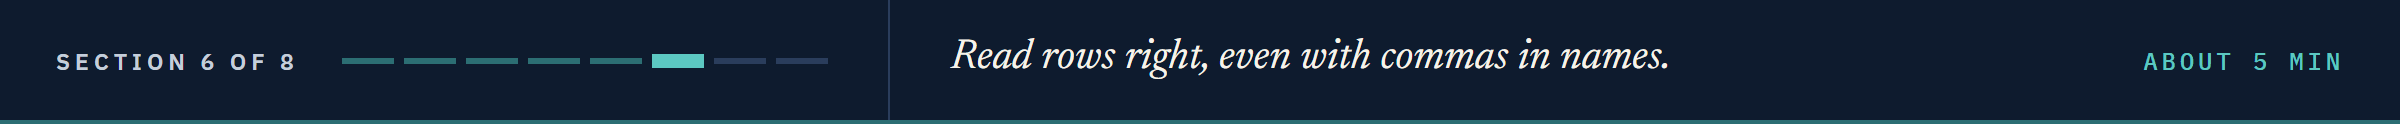

## 2.6 The csv Module

### A Comma Inside a Name

Suppose each line also carried the issuer's name, such as `Quorvane Energy, Inc.`
CSV wraps a value that holds a comma in quotes.

Q. Split that line at the commas and count the pieces.

Q. Then read the same line with the `csv` module, which comes with Python and knows the CSV rules.

In [22]:
# three values: ticker, issuer name, face
line = 'QVNE,"Quorvane Energy, Inc.",1500000'
values = line.split(',')
print(values)
print(f'{len(values)} pieces; index 2 holds {values[2]}')

['QVNE', '"Quorvane Energy', ' Inc."', '1500000']
4 pieces; index 2 holds  Inc."


In [23]:
# load the csv module, which comes with Python
import csv
# csv.reader() takes lines of text and hands back each as a list of values: here, one line
for values in csv.reader([line]):
    print(values)
    print(f'{len(values)} values; index 2 holds {values[2]}')

['QVNE', 'Quorvane Energy, Inc.', '1500000']
3 values; index 2 holds 1500000


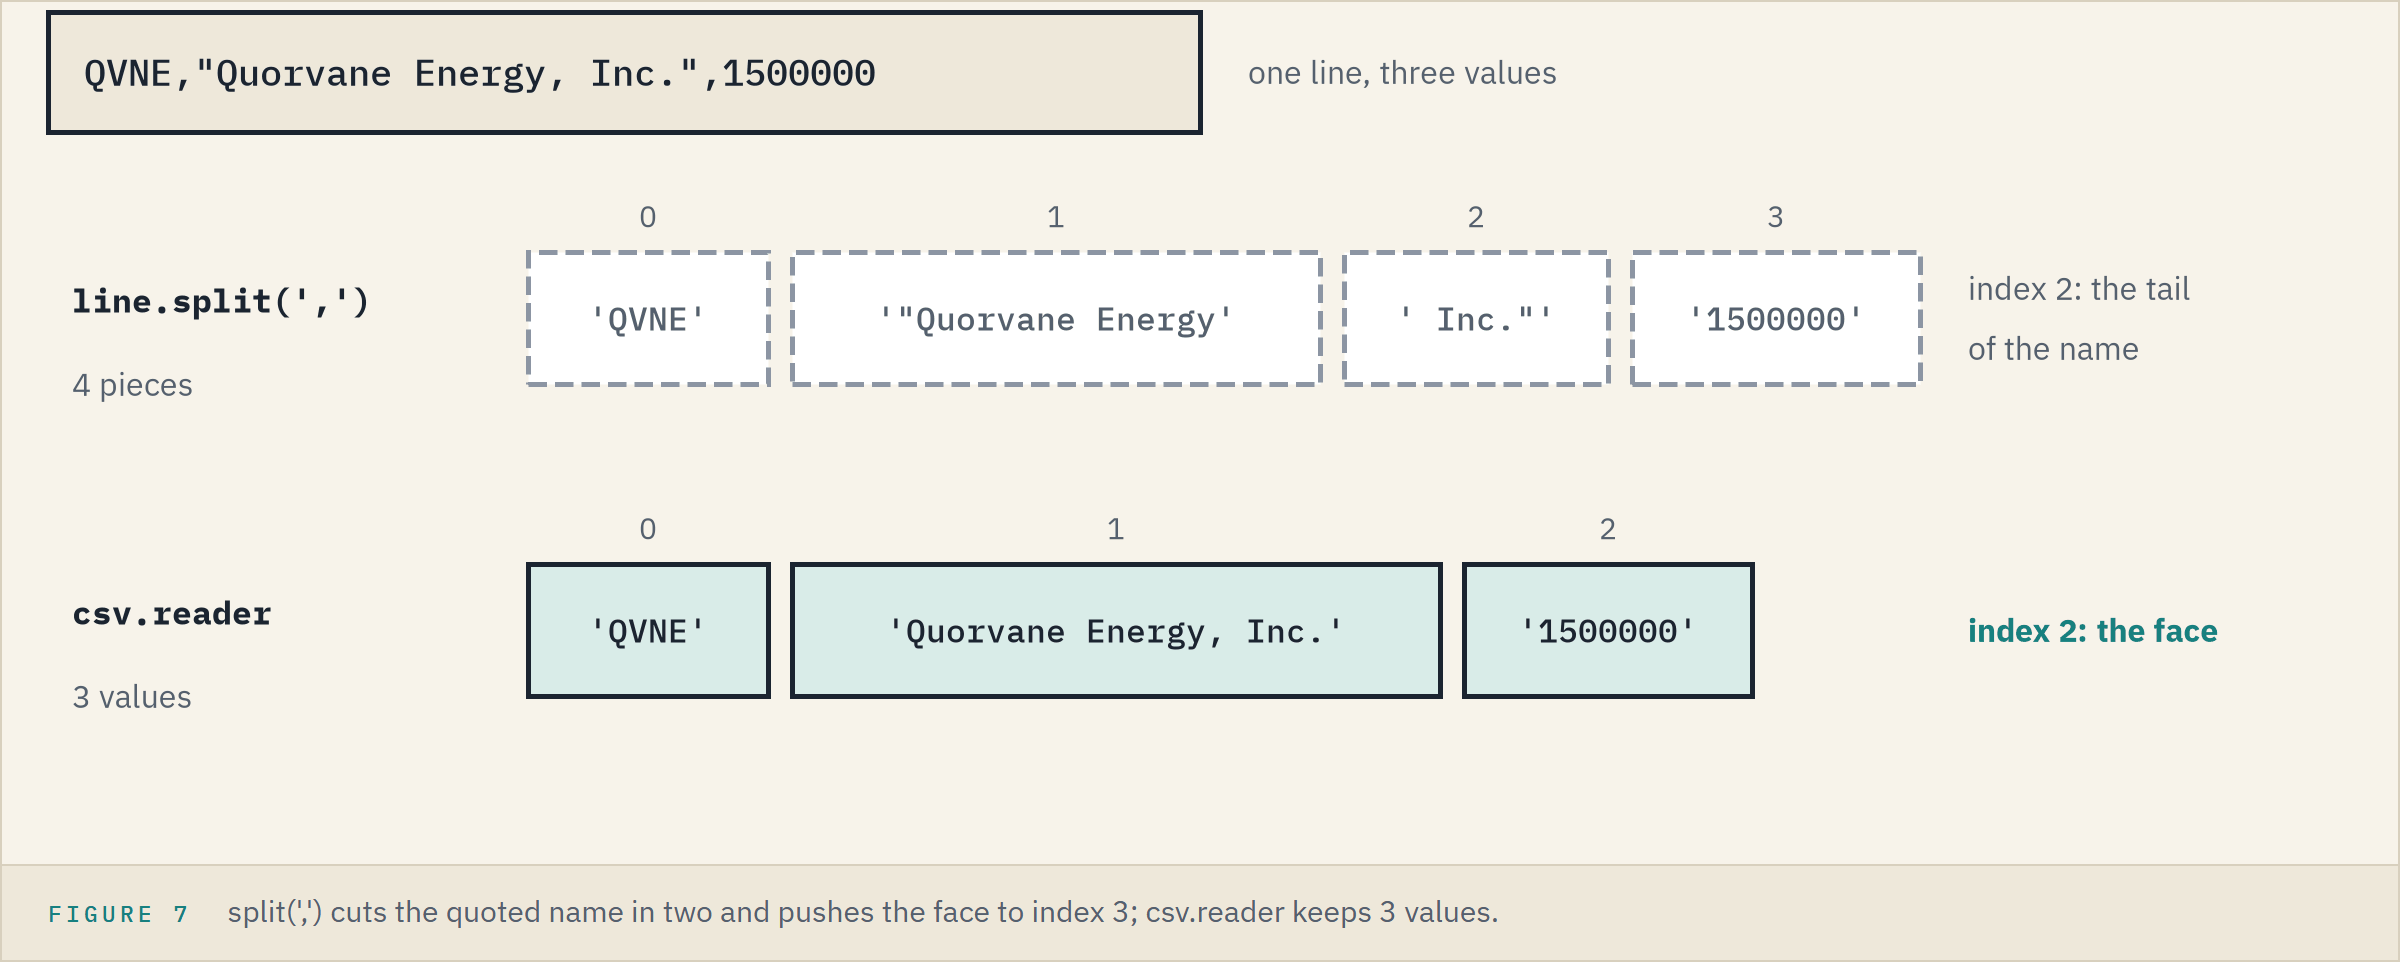

Split at the commas: 4 pieces, no error, and index 2 holds the tail of the name.
`csv.reader`: 3 values, the quoted comma kept in the name, the face back at index 2.

**Excel side by side.** Excel opens that line the same way: `Quorvane Energy, Inc.` in one cell, the face in the third column.

**Now the whole file.**

### Read the Whole File

Q. Read the book with `csv.reader`: how many rows, and what do the first two look like?

In [24]:
# newline='' leaves the line endings to the csv module, as its documentation asks
with open(file_path, 'r', encoding='utf-8', newline='') as file:
    # list() collects every row the reader hands back
    rows = list(csv.reader(file))
print(len(rows))
print(rows[0])
print(rows[1])

5
['Ticker', 'Coupon', 'Price', 'Face']
['QVNE', '5.25', '98.5', '1500000']


5 rows, each already a list with no `\n`; the values are still strings.

**Index 3 breaks if a column moves. Use names.**

### Read by Column Name

`csv.DictReader` hands back each bond as a dictionary, keyed by the header line's names.

Q. Total the book's cost from the file: face times price, divided by 100.

Q. Now the whole file with pandas, Day 0's table library.

In [25]:
# look each value up by its column name, and convert it from text
total_cost = 0
with open(file_path, 'r', encoding='utf-8', newline='') as file:
    for row in csv.DictReader(file):
        total_cost += int(row['Face']) * float(row['Price']) / 100
print(f'The book cost ${total_cost:,.2f}')

The book cost $2,958,750.00


In [26]:
# pandas, as on Day 0; read_csv() reads the whole file into a table
import pandas as pd
pd.read_csv(file_path)

,Ticker,Coupon,Price,Face
0,QVNE,5.250,98.50,1500000
1,DNMR,6.125,103.25,500000
2,PLWK,4.750,95.00,750000
3,HLVF,7.500,101.00,250000


2,958,750.00 dollars, Part 2's cost: the whole book came back.
`row['Face']` names what it reads and survives a column move.
pandas reads the whole file into a table in one line, the numbers already numbers: week 2 starts there.

**Other people's code writes paths a second way.**

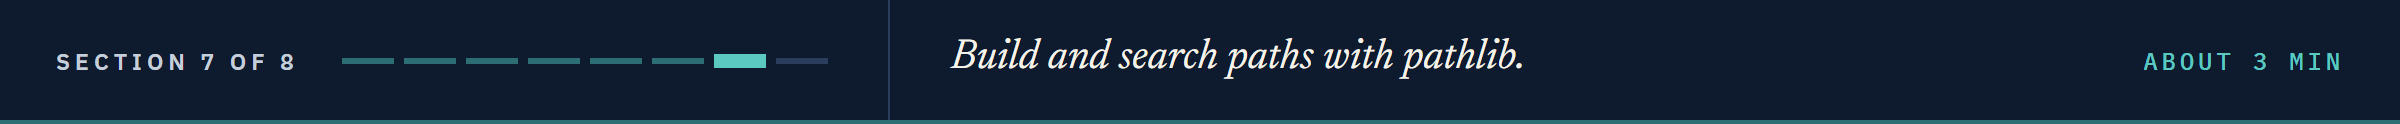

## 2.7 Paths With pathlib

### A Path That Knows Itself

`os` treats a path as text; the newer `pathlib` makes a path that carries its own answers.
You will meet both in other people's code.

Q. Build the path to the holdings file again, this time with `pathlib`.

Q. Does the file exist? What is its name, and which folder is it in?

In [27]:
# Path is the one name we need from pathlib, taken as Day 0 took date from datetime
from pathlib import Path
# Path() makes the first part a path; after it, / joins the parts instead of dividing
holdings_path = Path('desk_holdings') / '2026-10-02' / 'holdings.csv'
print(holdings_path)

desk_holdings\2026-10-02\holdings.csv


In [28]:
# exists() is a method of the path: reached with a dot
print(holdings_path.exists())
# name is the last part; parent is the folder it sits in, a path with its own name
print(holdings_path.name)
print(holdings_path.parent)
print(holdings_path.parent.name)

True
holdings.csv
desk_holdings\2026-10-02
2026-10-02


The same path `os.path.join()` built, with the separator chosen for you.
`exists()` runs a check, so it takes brackets; `name` and `parent` are parts the path already holds, read with no brackets, as `.days` was on Day 0.

**It can also search its own folder.**

### Find the CSV Files

Q. List the CSV files in the dated folder.

In [29]:
# glob() finds the names that match a pattern; * stands for any text
csv_names = [path.name for path in holdings_path.parent.glob('*.csv')]
print(csv_names)

['holdings.csv']


One step, where `os` took `listdir()` and `endswith()`.

<table align="left">
<tr><th align="left">Job</th><th align="left">With os</th><th align="left">With pathlib</th></tr>
<tr><td align="left">Join the parts of a path</td><td align="left"><code>os.path.join('desk_holdings', '2026-10-02')</code></td><td align="left"><code>Path('desk_holdings') / '2026-10-02'</code></td></tr>
<tr><td align="left">Check that it exists</td><td align="left"><code>os.path.exists(path)</code></td><td align="left"><code>path.exists()</code></td></tr>
<tr><td align="left">Take the last part</td><td align="left"><code>os.path.basename(path)</code></td><td align="left"><code>path.name</code></td></tr>
<tr><td align="left">Find the files that match</td><td align="left"><code>os.listdir()</code> with <code>endswith()</code></td><td align="left"><code>path.glob('*.csv')</code></td></tr>
</table>
<br clear="left">

A `Path` works in `open()`, and in pandas next week, wherever a text path does.

**Excel side by side.** `*` is Excel's wildcard too: with file names in A1:A10, `=COUNTIF(A1:A10,"*.csv")` counts the names that end in .csv.

**The desk lead has spotted a wrong date.**

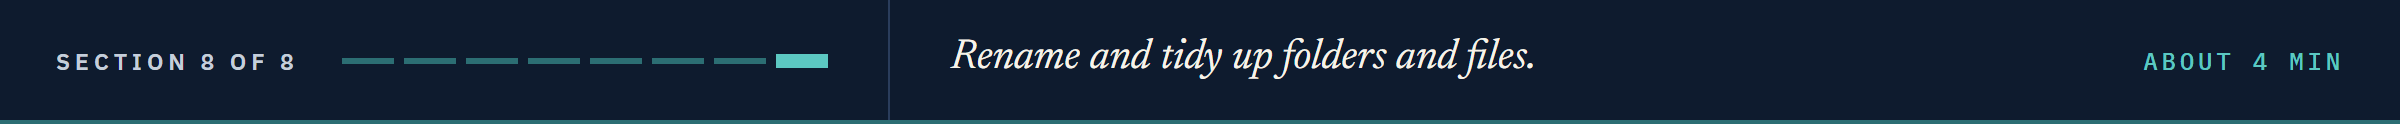

## 2.8 Move and Tidy

### Fix the Date

Q. The file belongs to October 3. Rename the dated folder.

In [30]:
# rename() takes the old name, then the new one
new_day_folder = os.path.join('desk_holdings', '2026-10-03')
os.rename(day_folder, new_day_folder)
print(os.listdir('desk_holdings'))
print(os.listdir(new_day_folder))

['2026-10-03']
['holdings.csv']


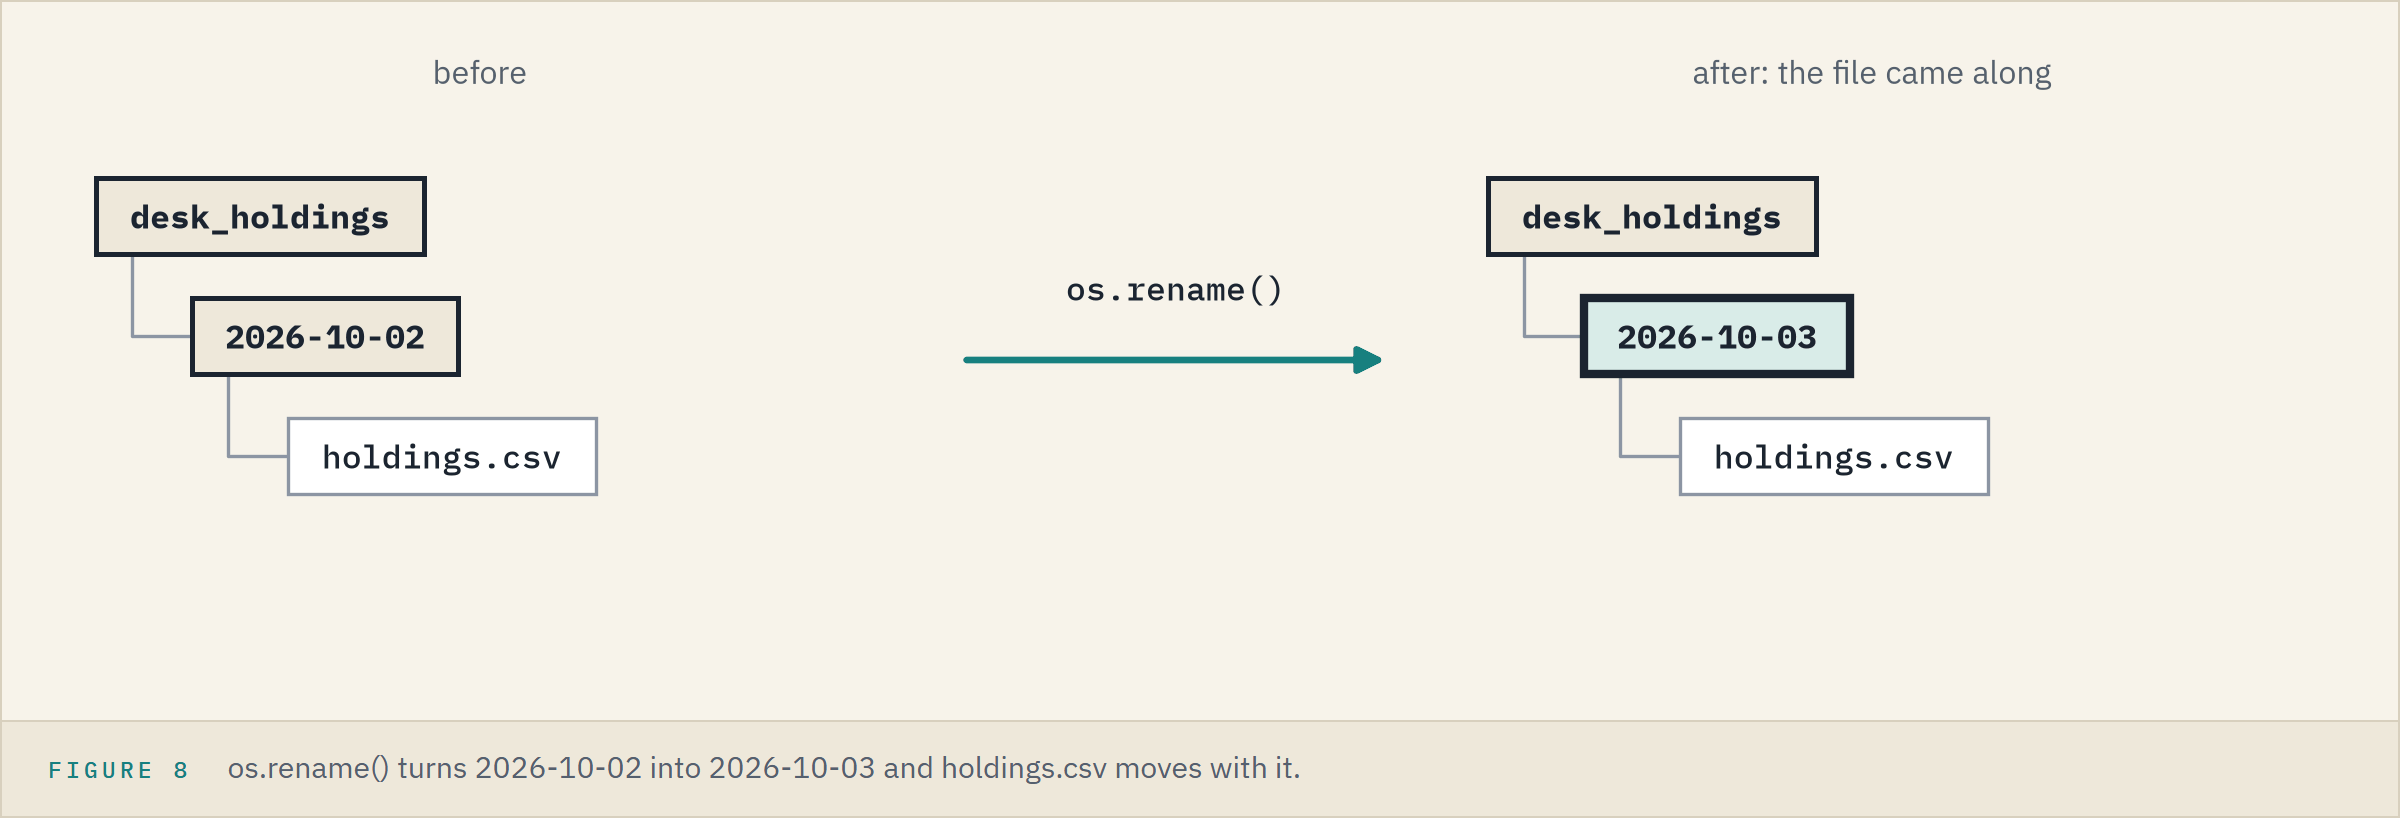

The file moved with its folder, intact, and sits on your disk: open it in Excel if you like, then close it before you run on, because Windows will not delete a file another program has open.
Rename only to a name not in use: Windows refuses with `FileExistsError`, but macOS, Linux, and Colab replace a file of that name without a word.

**A lesson tidies up so it runs again; a desk would keep this folder.**

### Delete the File, Then the Folders

Q. Delete the holdings file.

Q. Remove 'desk_holdings' while the dated folder is still inside it.

Q. Then remove the inner folder, then the outer one.

In [31]:
# remove() deletes a file; there is no recycle bin, so be sure first
os.remove(os.path.join(new_day_folder, 'holdings.csv'))
print(os.listdir(new_day_folder))

[]


In [32]:
# desk_holdings still holds a folder: this cell is meant to fail
os.rmdir('desk_holdings')

OSError: [WinError 145] The directory is not empty: 'desk_holdings'

In [33]:
# rmdir() removes a folder only when it is empty: inner first, then outer
os.rmdir(new_day_folder)
os.rmdir('desk_holdings')
print(os.path.exists('desk_holdings'))

False


`rmdir()` refuses a folder that is not empty, a safety feature: the inner folder had to go first.
The working directory is back as we found it.

**Now the second desk's trades are yours.**

## You Can Now

By the end of this notebook, you can:

* See which folder Python works in and what it holds.
* Make, rename, and remove folders, with paths that work on any machine.
* Write a file, its rows by a loop.
* Read a file line by line or with `csv`, and total a column.
* Turn text from a file into numbers before you calculate.

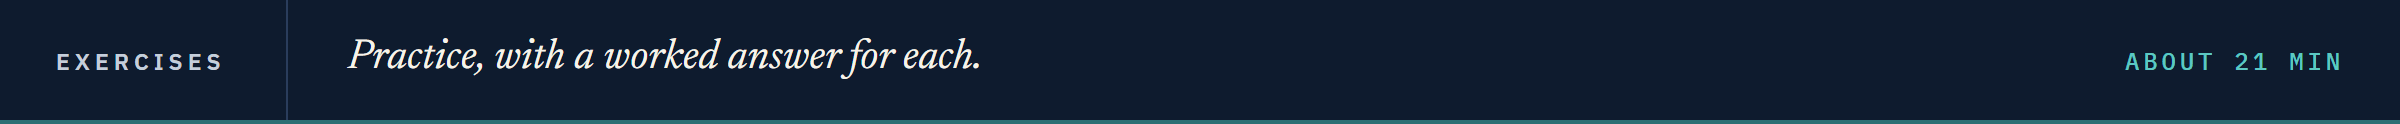

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

A second desk bought three bonds today.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Face bought</th><th align="left">Price</th></tr>
<tr><td align="left">TRNW</td><td align="left">2,000,000</td><td align="left">96.25</td></tr>
<tr><td align="left">OSMC</td><td align="left">1,250,000</td><td align="left">100.00</td></tr>
<tr><td align="left">CLDB</td><td align="left">500,000</td><td align="left">104.50</td></tr>
</table>
<br clear="left">

Run the next cell first: it defines `check` and clears earlier attempts.
Then replace each `...` and run the check cell under it.

In [34]:
def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
    elif answer == expected:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)

import os
import shutil
# remove anything left over from an earlier attempt
for folder in ['blotter', 'trade_blotter']:
    shutil.rmtree(folder, ignore_errors=True)
if os.path.exists('ai_holdings.csv'):
    os.remove('ai_holdings.csv')

### Exercise 1

Q. Create a folder named 'blotter'. Then store whether it exists in **ex1_exists**.

In [35]:
ex1_exists = ...

In [36]:
check('Exercise 1', ex1_exists, True)

Exercise 1: not attempted yet


### Exercise 2

Q. Write 'trades.csv' inside 'blotter', with the header line `Ticker,Face,Price` and a line for each trade.
Then read it back and store the number of lines in **ex2_line_count**.

In [37]:
ex2_line_count = ...

In [38]:
check('Exercise 2', ex2_line_count, 4)

Exercise 2: not attempted yet


### Exercise 3

Q. Read 'trades.csv' and work out the total cost of the three trades: face times price, divided by 100 (the clean price, with accrued interest left out).
Store the answer in **ex3_total_cost**.

In [39]:
ex3_total_cost = ...

In [40]:
check('Exercise 3', ex3_total_cost, 3697500.0)

Exercise 3: not attempted yet


### Exercise 4

Q. Rename the 'blotter' folder to 'trade_blotter'. Then store the list of files inside it in **ex4_files**.

In [41]:
ex4_files = ...

In [42]:
check('Exercise 4', ex4_files, ['trades.csv'])

Exercise 4: not attempted yet


### Exercise 5

Q. Use `pathlib` to build the path to 'trades.csv' inside 'trade_blotter'.
Store whether the file exists in **ex5_exists**, and the name of the folder it sits in in **ex5_folder**.

In [43]:
from pathlib import Path

ex5_exists = ...
ex5_folder = ...

In [44]:
check('Exercise 5 exists', ex5_exists, True)
check('Exercise 5 folder', ex5_folder, 'trade_blotter')

Exercise 5 exists: not attempted yet
Exercise 5 folder: not attempted yet


### Exercise 6

Q. Read 'trades.csv' in 'trade_blotter' with `csv.DictReader` and total the Face column.
Store the total in **ex6_total_face**.

In [45]:
import csv

ex6_total_face = ...

In [46]:
check('Exercise 6', ex6_total_face, 3750000)

Exercise 6: not attempted yet


### Exercise 7: AI check

An AI assistant wrote code to create a small holdings file and add one more bond; it has one bug.

Q. Read the code before you run it. A header, three bonds, and one more bond: how many lines should the file have? Then run it.

In [47]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# create the file with a header and three bonds
with open('ai_holdings.csv', 'w', encoding='utf-8') as file:
    file.write('Ticker,Face\n')
    file.write('TRNW,2000000\n')
    file.write('OSMC,1250000\n')
    file.write('CLDB,500000\n')

# add one more bond to the file
with open('ai_holdings.csv', 'w', encoding='utf-8') as file:
    file.write('QVNE,1500000\n')

# count the lines in the file
with open('ai_holdings.csv', 'r', encoding='utf-8') as file:
    print(f'Lines in the file: {len(file.readlines())}')

Lines in the file: 1


Q. Is that believable? Find the bug, fix it so the file has every line it should, and store the line count in **ex7_line_count**.

In [48]:
ex7_line_count = ...

In [49]:
check('Exercise 7', ex7_line_count, 5)

Exercise 7: not attempted yet


When you finish, run this cell: it removes what the exercises made.

In [50]:
for folder in ['blotter', 'trade_blotter']:
    shutil.rmtree(folder, ignore_errors=True)
if os.path.exists('ai_holdings.csv'):
    os.remove('ai_holdings.csv')

## Congratulations!

This morning the book lived only in a running notebook; now it has a folder and a file, and the note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">A folder of its own</td><td align="left"><code>desk_holdings</code>, a folder per day inside</td></tr>
<tr><td align="left">Write it to a file</td><td align="left"><code>holdings.csv</code>, four bonds by one loop</td></tr>
<tr><td align="left">3,000,000 face read back</td><td align="left">3,000,000, by <code>split</code></td></tr>
<tr><td align="left">2,958,750 dollars of cost read back</td><td align="left">2,958,750.00, by <code>csv.DictReader</code></td></tr>
</table>
<br clear="left">

Until today you typed the book; now it comes out of a file, the way real data reaches a desk.
Be proud of that.
You met four errors on purpose and read each from its last line.
On Day 3 errors become the lesson: you read a whole traceback and fix the line it points at.

[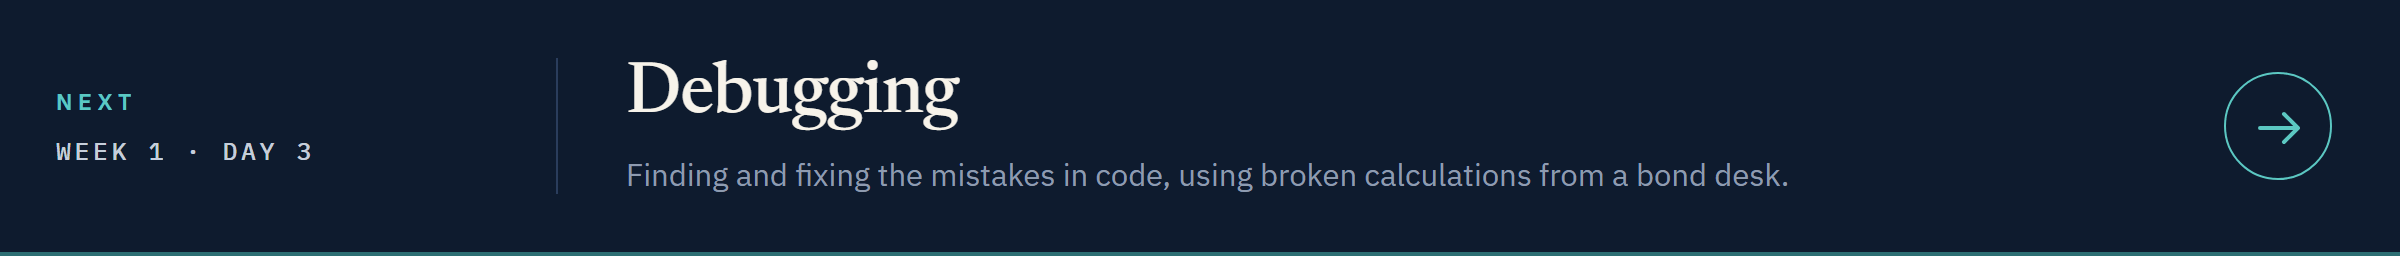](../day3/03_debugging.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day3/03_debugging.ipynb)